# 02 · Fraud Model: Build, Compare, and Turn into a Business Decision
The EDA showed six fraud signals that each work alone but overlap heavily. This notebook combines them in a model and answers the business question:

> **With capacity to investigate only 10% of claims, which claims should the SIU pick, and how much more fraud does that stop than today's rules engine?**

**Approach**
1. Use point-in-time features built in SQL (`sql/05_feature_engineering.sql`) and guard against leakage.
2. Do an **out-of-time** split: train on 2022–23, tune on 2024, test once on 2025.
3. Compare a rules baseline, Logistic Regression, Random Forest and Gradient Boosting.
4. Judge them on **business metrics**: precision and recall at SIU capacity, fraud ₹ caught, and net benefit.
5. Explain the model with permutation importance and per-claim reason codes for investigators.

All logic lives in `src/modeling.py`. `src/train_model.py` runs the same steps as a script.

In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import modeling as M
import plots as P
P.setup_style()
pd.set_option("display.float_format", "{:,.3f}".format)

df = M.load_features()
print(f"{df.shape[0]:,} claims x {df.shape[1]} columns | {len(M.FEATURES)} model features "
      f"({len(M.CATEGORICAL)} categorical, {len(M.NUMERIC)} numeric)")

16,810 claims x 56 columns | 51 model features (9 categorical, 42 numeric)


## 1. Leakage check
Leakage means a feature that wouldn't be known when the claim is scored. It makes models look brilliant in testing and fail in production. The controls:

| Risk | Control |
|---|---|
| `claim_status`, `settled_amount` are decided *after* investigation | Excluded from the feature table (asserted in `load_features`) |
| Garage/agent fraud history could include the claim itself or still-open cases | Uses only claims reported **≥ 90 days earlier** (closed investigations), smoothed toward a 10% prior |
| Customer claim history could peek at future claims | Window functions count only **prior** claims (`RANGE ... 1 PRECEDING`) |
| Random train/test split mixes future and past | **Out-of-time split** by incident year |

In [2]:
assert not set(M.LEAKAGE_COLS) & set(df.columns)
train, valid, test = M.time_split(df)
pd.DataFrame({
    "period": ["2022-2023", "2024", "2025"],
    "role": ["train", "validation (model selection)", "test (touched once)"],
    "claims": [len(train), len(valid), len(test)],
    "fraud_rate": [train.is_fraud.mean(), valid.is_fraud.mean(), test.is_fraud.mean()],
}, index=["train", "valid", "test"])

,period,role,claims,fraud_rate
train,2022-2023,train,6989,0.108
valid,2024,validation (model selection),4767,0.099
test,2025,test (touched once),5054,0.096


## 2. Choosing the right metric
With a ~10% fraud rate, **accuracy is useless**: predicting "genuine" for every claim scores 90%. What we use instead:
- **PR-AUC** (average precision) as the main statistical metric. It focuses on the rare positive class.
- **Precision & recall @ 10% capacity**: of the claims the SIU actually investigates, how many are fraud, and what share of all fraud is caught?
- **Fraud value recall and net benefit (₹)**, because a ₹8 lakh fraud matters more than a ₹15,000 one.

Business assumptions (all in `src/modeling.py`, easy to challenge):

In [3]:
pd.Series({
    "SIU capacity (share of claims investigated)": f"{M.SIU_CAPACITY:.0%}",
    "Cost per investigation": f"₹{M.COST_PER_INVESTIGATION:,}",
    "Share of a caught fraud claim actually saved": f"{M.RECOVERY_RATE:.0%}",
    "Friction cost of investigating a genuine customer": f"₹{M.FALSE_POSITIVE_FRICTION:,}",
}, name="assumption").to_frame()

,assumption
SIU capacity (share of claims investigated),10%
Cost per investigation,"₹5,000"
Share of a caught fraud claim actually saved,60%
Friction cost of investigating a genuine customer,"₹15,000"


## 3. Model selection on the 2024 validation year

In [4]:
candidates = {"Logistic Regression": M.make_logistic(), "Random Forest": M.make_random_forest()}
grid = [dict(learning_rate=lr, max_leaf_nodes=lv, class_weight=cw)
        for lr in (0.03, 0.06) for lv in (15, 31) for cw in (None, "balanced")]
for g in grid:
    candidates[f"GB lr={g['learning_rate']} leaves={g['max_leaf_nodes']} cw={g['class_weight']}"] = M.make_gradient_boosting(**g)

rows = [{"model": "Rules engine (baseline)", **M.evaluate(valid.is_fraud, valid.red_flag_score, valid.total_claim_amount)}]
for name, pipe in candidates.items():
    pipe.fit(train[M.FEATURES], train.is_fraud)
    rows.append({"model": name, **M.evaluate(valid.is_fraud, pipe.predict_proba(valid[M.FEATURES])[:, 1],
                                             valid.total_claim_amount)})
val = pd.DataFrame(rows).sort_values("pr_auc", ascending=False).reset_index(drop=True)
val[["model", "roc_auc", "pr_auc", "precision_at_capacity", "recall_at_capacity"]]

,model,roc_auc,pr_auc,precision_at_capacity,recall_at_capacity
0,GB lr=0.03 leaves=15 cw=None,0.831,0.414,0.430,0.432
1,GB lr=0.06 leaves=15 cw=None,0.829,0.414,0.438,0.441
2,GB lr=0.06 leaves=15 cw=balanced,0.828,0.410,0.421,0.424
3,GB lr=0.03 leaves=15 cw=balanced,0.831,0.409,0.423,0.426
4,GB lr=0.06 leaves=31 cw=balanced,0.825,0.407,0.417,0.420
5,GB lr=0.03 leaves=31 cw=None,0.825,0.407,0.434,0.437
6,GB lr=0.03 leaves=31 cw=balanced,0.827,0.406,0.438,0.441
7,Random Forest,0.821,0.404,0.409,0.411
8,GB lr=0.06 leaves=31 cw=None,0.824,0.397,0.417,0.420
9,Logistic Regression,0.794,0.370,0.415,0.418


**Read-out**
- Every ML model beats the rules engine. The gap is largest on **PR-AUC**, the metric that matters for rare-event detection.
- **Gradient Boosting** wins. It captures interactions (e.g. *early claim × suspicious garage*) that a linear model can't.
- **Class imbalance:** `class_weight="balanced"` did *not* help the boosted model's ranking. It also distorts probabilities, which we need calibrated to compute *expected ₹ loss*, so the unweighted version is kept. (SMOTE-style oversampling was avoided for the same reason.)

In [5]:
best_name = val[val.model.str.startswith("GB ")].iloc[0].model
best_params = grid[[f"GB lr={g['learning_rate']} leaves={g['max_leaf_nodes']} cw={g['class_weight']}" for g in grid].index(best_name)]
print("Selected:", best_name)

# Ranking strategy, also decided on validation: rank by fraud probability, or by expected loss = p x claim amount?
p_val = candidates[best_name].predict_proba(valid[M.FEATURES])[:, 1]
pd.DataFrame({
    "rank by probability": M.top_k_metrics(valid.is_fraud, p_val, valid.total_claim_amount),
    "rank by expected ₹ loss": M.top_k_metrics(valid.is_fraud, p_val * valid.total_claim_amount, valid.total_claim_amount),
}).loc[["precision_at_capacity", "recall_at_capacity", "fraud_amount_recall", "net_benefit"]]

Selected: GB lr=0.03 leaves=15 cw=None


,rank by probability,rank by expected ₹ loss
precision_at_capacity,0.430,0.317
recall_at_capacity,0.432,0.319
fraud_amount_recall,0.467,0.726
net_benefit,"24,536,700.000","40,975,560.000"


**Key business decision:** ranking the queue by **expected ₹ loss** (probability × claim amount) catches slightly fewer fraud *cases* but much more fraud *value*. That gives a higher net benefit, so the investigation queue is ordered by expected loss. A pure data-science approach would stop at "highest probability first". The business framing changes the answer.

## 4. Final evaluation on 2025 (untouched hold-out)
Re-fit on 2022–2024 and score 2025 once.

In [6]:
trval = pd.concat([train, valid])
final = {"Logistic Regression": M.make_logistic(), "Random Forest": M.make_random_forest(),
         "Gradient Boosting": M.make_gradient_boosting(**best_params)}
y, amt = test.is_fraud.to_numpy(), test.total_claim_amount.to_numpy()
scores = {"Rules engine (baseline)": test.red_flag_score.to_numpy(float)}
for name, pipe in final.items():
    pipe.fit(trval[M.FEATURES], trval.is_fraud)
    scores[name] = pipe.predict_proba(test[M.FEATURES])[:, 1]
gb_p = scores["Gradient Boosting"]

res = pd.DataFrame([{"model": n, **M.evaluate(y, s, amt)} for n, s in scores.items()] +
                   [{"model": "Gradient Boosting · ranked by expected ₹ loss", **M.evaluate(y, gb_p * amt, amt)}])
res["net_benefit_cr"] = res.net_benefit / 1e7
res[["model", "roc_auc", "pr_auc", "precision_at_capacity", "recall_at_capacity", "fraud_amount_recall", "net_benefit_cr"]]

,model,roc_auc,pr_auc,precision_at_capacity,recall_at_capacity,fraud_amount_recall,net_benefit_cr
0,Rules engine (baseline),0.735,0.236,0.311,0.325,0.399,1.994
1,Logistic Regression,0.810,0.393,0.414,0.433,0.487,2.689
2,Random Forest,0.834,0.430,0.436,0.455,0.529,2.995
3,Gradient Boosting,0.849,0.463,0.465,0.487,0.568,3.291
4,Gradient Boosting · ranked by expected ₹ loss,0.784,0.350,0.356,0.373,0.741,4.408


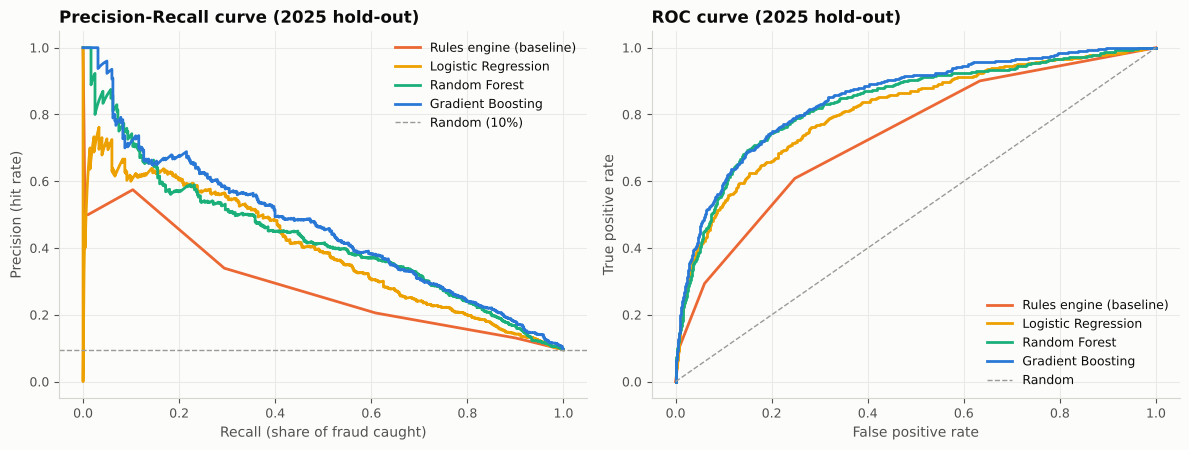

In [7]:
fig = P.pr_roc_curves(y, scores)

## 5. From model to decision: how many claims should the SIU review?

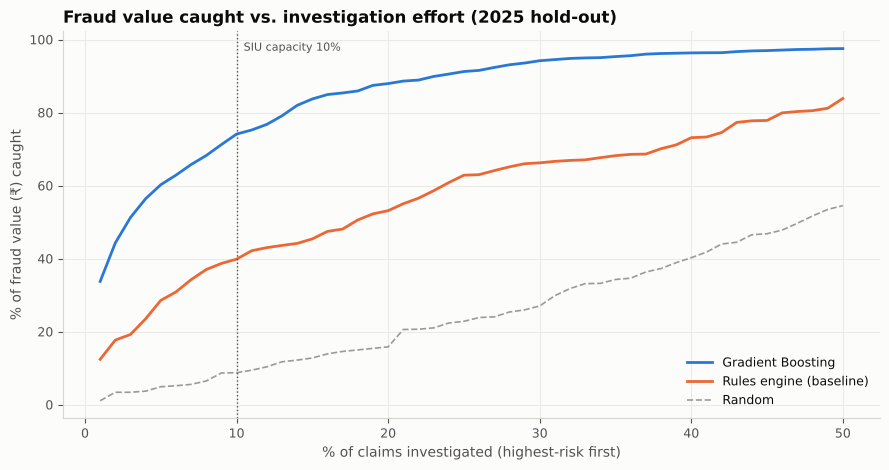

In [8]:
rng = np.random.default_rng(0)
curves = {"Gradient Boosting": M.capacity_curve(y, gb_p * amt, amt),
          "Rules engine (baseline)": M.capacity_curve(y, scores["Rules engine (baseline)"], amt),
          "Random": M.capacity_curve(y, rng.random(len(y)), amt)}
fig = P.capacity_chart(curves, M.SIU_CAPACITY, metric="fraud_amount_recall", ylabel="% of fraud value (₹) caught",
                       title="Fraud value caught vs. investigation effort (2025 hold-out)")

At 10% capacity  -> model: 74% of fraud value, net ₹4.41 Cr | rules: 40%, net ₹1.99 Cr
Model optimum    -> review 15% of claims, net ₹4.66 Cr


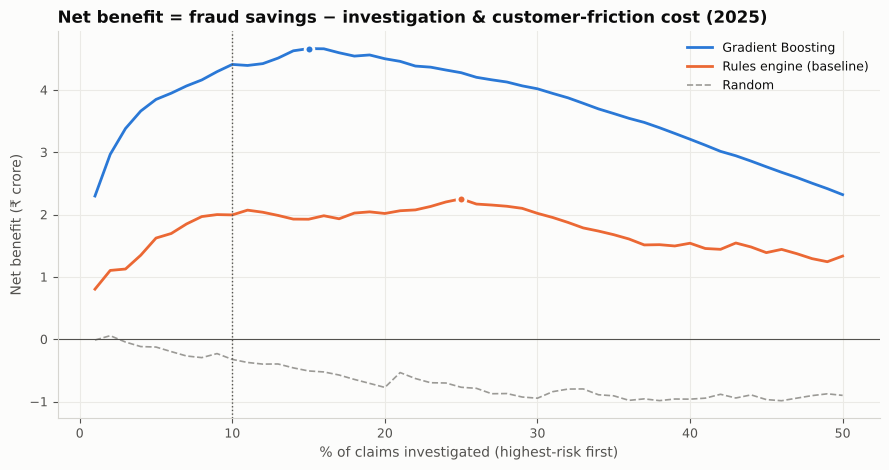

In [9]:
fig = P.net_benefit_chart(curves, M.SIU_CAPACITY)
gb_c, rb_c = curves["Gradient Boosting"], curves["Rules engine (baseline)"]
opt = gb_c.loc[gb_c.net_benefit.idxmax()]
at10_gb = gb_c.loc[np.isclose(gb_c.pct_reviewed, M.SIU_CAPACITY)].iloc[0]
at10_rb = rb_c.loc[np.isclose(rb_c.pct_reviewed, M.SIU_CAPACITY)].iloc[0]
print(f"At 10% capacity  -> model: {at10_gb.fraud_amount_recall:.0%} of fraud value, net ₹{at10_gb.net_benefit/1e7:.2f} Cr | "
      f"rules: {at10_rb.fraud_amount_recall:.0%}, net ₹{at10_rb.net_benefit/1e7:.2f} Cr")
print(f"Model optimum    -> review {opt.pct_reviewed:.0%} of claims, net ₹{opt.net_benefit/1e7:.2f} Cr")

**Read-out**
- At the **same 10% workload**, the model catches roughly **twice the fraud value** of the rules engine, with about twice the net benefit, on a year of data it never saw.
- The model's net-benefit curve peaks around **12–15% of claims**. Each extra investigation up to that point still pays for itself (including the cost of inconveniencing genuine customers). That supports a case for adding modest SIU capacity, and the curve is flat near the top, so the gain from going past 10% is small. The first priority is to **reorder the existing queue**.
- Past the peak, net benefit falls. Investigating everyone would cost more than it saves.

## 6. Why does the model flag a claim? (explainability)

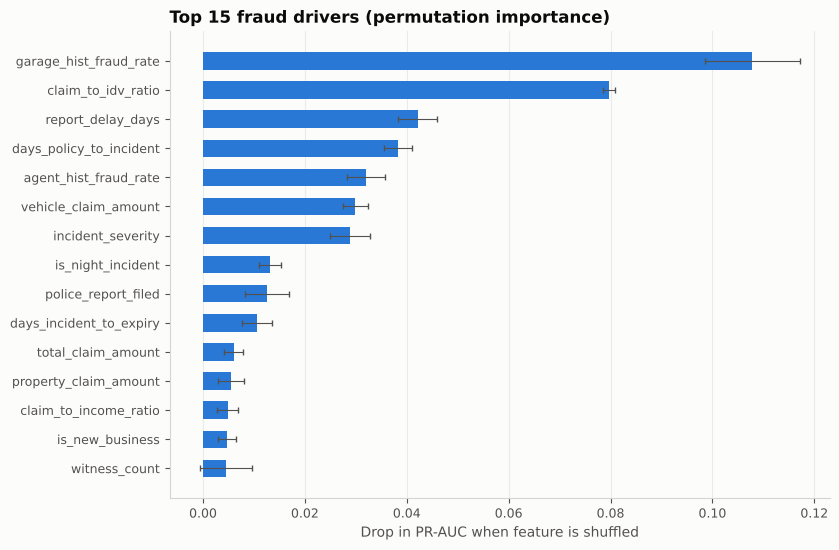

In [10]:
pi = permutation_importance(final["Gradient Boosting"], test[M.FEATURES], y, scoring="average_precision",
                            n_repeats=5, random_state=M.RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"feature": M.FEATURES, "importance": pi.importances_mean, "std": pi.importances_std}) \
        .sort_values("importance", ascending=False)
fig = P.importance_chart(imp)

The top drivers line up with the EDA hypotheses: **garage fraud history (H5)**, **claim vs insured value (H6)**, **reporting delay (H2)**, **days since policy start (H1)** and **agent history (H5)**. A model whose drivers make business sense is much easier to get signed off by an SIU head or a regulator.

Investigators don't read feature-importance charts, though. Each flagged claim gets **plain-English reason codes**:

In [11]:
queue = test[["claim_id", "claim_type", "incident_severity", "total_claim_amount"]].copy()
queue["fraud_probability"] = gb_p
queue["expected_loss"] = gb_p * amt
queue["reasons"] = M.reason_codes(test).values
queue["actual_outcome"] = np.where(test.is_fraud == 1, "Fraud", "Genuine")
top = queue.sort_values("expected_loss", ascending=False).head(10)
with pd.option_context("display.max_colwidth", 120, "display.float_format", "{:,.2f}".format):
    display_top = top.style.format({"total_claim_amount": "₹{:,.0f}", "expected_loss": "₹{:,.0f}",
                                    "fraud_probability": "{:.0%}"}).hide(axis="index")
display_top

claim_id,claim_type,incident_severity,total_claim_amount,fraud_probability,expected_loss,reasons,actual_outcome
CL3015876,Third Party Injury,Major,"₹2,749,500",69%,"₹1,908,002",Agent has high historical fraud rate; Claim within 30 days of policy start; Night-time incident (00:00-05:00),Fraud
CL3012661,Fire,Total Loss,"₹1,680,000",84%,"₹1,416,839",Garage has high historical fraud rate; Agent has high historical fraud rate; Claim within 30 days of policy start,Fraud
CL3004656,Vandalism,Total Loss,"₹1,324,000",85%,"₹1,120,583",Garage has high historical fraud rate; Agent has high historical fraud rate; Night-time incident (00:00-05:00),Fraud
CL3010353,Third Party Injury,Major,"₹1,290,900",70%,"₹899,755",Reported more than 7 days late; Night-time incident (00:00-05:00); No police report on major loss,Fraud
CL3003386,Theft,Total Loss,"₹1,391,000",64%,"₹890,526",Agent has high historical fraud rate; Reported more than 7 days late; Policy recently ported from another insurer,Fraud
CL3012824,Third Party Injury,Major,"₹1,529,600",52%,"₹799,621",Claim within 30 days of policy start; Reported more than 7 days late; Repeat claimant (claim in last 12 months),Fraud
CL3016360,Flood,Total Loss,"₹1,392,000",55%,"₹769,440",Garage has high historical fraud rate; Agent has high historical fraud rate; No police report on major loss,Fraud
CL3015360,Collision,Major,"₹785,900",90%,"₹708,943",Garage has high historical fraud rate; Claim within 30 days of policy start; Reported more than 7 days late,Fraud
CL3001617,Flood,Total Loss,"₹914,000",69%,"₹633,952",Garage has high historical fraud rate; Claim within 30 days of policy start; Reported more than 7 days late,Fraud
CL3002158,Collision,Total Loss,"₹1,550,100",38%,"₹591,959",Garage has high historical fraud rate; Claim within 30 days of policy start,Fraud


## 7. Recommendations
1. **Replace the rules-based SIU queue with the model-ranked queue (by expected ₹ loss).** Same team, about twice the fraud value caught: **~₹2.4 Cr extra net benefit a year** on this portfolio.
2. **Investigate the network, not just claims.** A handful of garages and agents run at 3–5× the average fraud rate. Audit them, review cashless-network status for the worst garages, and claw back agent commissions where fraud is confirmed.
3. **Add friction at the points of highest risk:** mandatory photo/video inspection for claims in the first 30 days of a policy, and for major losses reported more than 7 days late or without a police report.
4. **Consider adding 2–5 points of SIU capacity.** Net benefit stays positive up to ~12–15% of claims reviewed.
5. **Monitor and retrain:** track monthly precision in the queue and feature drift. Retrain quarterly as new investigation outcomes close.

**Limitations:** the data is synthetic (patterns modelled on known industry red flags). The labels only cover *detected* fraud. The ₹ assumptions should be validated with the claims and SIU teams before rollout.